# Actividad 2-M1: simulación con Montecarlo y juego de Yahtzee

**Estudiante:** Daniela Sánchez  
**Materia:** Simulación
**Lenguaje:** Python — Google Colab

En este cuaderno voy a tomar el ejercicio de Montecarlo que vimos en clase y aplicarlo a otro caso: el juego de Yahtzee. Primero reviso la estimación de π, después hago la simulación de cinco dados y finalmente programo una partida para dos jugadores.

Voy a seguir las tres etapas de la actividad: **USA, MODIFICA y CREA**.

## 1. USA: ejercicio de π trabajado en clase

Este es el **código compartido por el profesor**. Lo dejo como punto de partida para que se note de dónde sale la idea de Montecarlo.

En resumen: se generan puntos aleatorios, se cuenta cuántos cumplen una condición y con esa cantidad se calcula una estimación.

In [11]:
import random # importación libreria random

def estimate_pi(n):
    # Contador de puntos dentro del círculo
    inside_circle = 0 # simepre los contadores se inicializan en cero

    for _ in range(n):
        # Generar punto aleatorio en [0,1] x [0,1]
        x = random.random()
        y = random.random()

        # Verificar si está dentro del círculo
        if x**2 + y**2 <= 1:# formula canonica de la circunferencia tomando los valores que estan dentro del circulo y el circulo
            inside_circle += 1 #acumulador que si ingresa al if me lo registra

    # Estimar π
    pi_estimate = 4 * inside_circle / n
    return pi_estimate

# Ejecutar simulación
n = 100000
pi = estimate_pi(n)
print(f"Estimación de π con {n} puntos: {pi:.5f}")
print(f"Error: {abs(pi - 3.14159):.5f}")


Estimación de π con 100000 puntos: 3.14668
Error: 0.00509


**¿Qué entendí de este ejemplo?**

- `random.random()` sirve para obtener valores aleatorios entre 0 y 1.
- `for` repite el experimento las veces que yo indique.
- `if` revisa si el punto está dentro del cuarto de círculo.
- El contador acumula los aciertos y con ellos se aproxima π.

El resultado puede cambiar cada vez que ejecute la celda, porque los puntos son aleatorios.

## 2. MODIFICA: de puntos aleatorios a cinco dados

En Yahtzee, cada dado puede tomar los valores 1, 2, 3, 4, 5 o 6. Voy a asumir que los dados son justos, independientes y que todas sus caras tienen la misma probabilidad: **1/6**.

El cambio frente al código de π es el siguiente:

| En el ejercicio de clase | En mi adaptación |
|---|---|
| Generar `x` e `y` | Lanzar cinco dados |
| Revisar si el punto entra en el círculo | Revisar si los cinco dados son iguales |
| Contador de puntos dentro | Contador de Yahtzees |
| Estimación de π | Frecuencia de Yahtzee |

En **una sola tirada** existen 6⁵ = 7.776 combinaciones posibles y 6 de ellas son Yahtzee. Por eso, la probabilidad teórica es **6/7.776 = 1/1.296 ≈ 0,07716 %**.

In [12]:
import random

# Una prueba sencilla para ver cómo salen los cinco dados.
random.seed(2026)  # Uso una semilla para repetir los resultados.
dados = [random.randint(1, 6) for _ in range(5)]
print("Dados obtenidos:", dados)

Dados obtenidos: [1, 3, 5, 5, 6]


In [13]:
def simular_yahtzee(n):
    """Calcula la frecuencia de Yahtzee en la primera tirada."""
    if n <= 0:
        raise ValueError("La cantidad de simulaciones debe ser mayor que cero")

    contador_yahtzee = 0
    suma_dados = 0

    for _ in range(n):
        dados = [random.randint(1, 6) for _ in range(5)]
        suma_dados += sum(dados)

        # Todos iguales significa que hay un Yahtzee.
        if len(set(dados)) == 1:
            contador_yahtzee += 1

    probabilidad = contador_yahtzee / n
    promedio_dado = suma_dados / (5 * n)
    return probabilidad, promedio_dado, contador_yahtzee

random.seed(2026)
probabilidad, promedio, veces = simular_yahtzee(100000)
print("Yahtzees encontrados:", veces)
print(f"Probabilidad estimada: {probabilidad * 100:.5f}%")
print(f"Promedio de los dados: {promedio:.5f}")

Yahtzees encontrados: 79
Probabilidad estimada: 0.07900%
Promedio de los dados: 3.49745


## 3. Comparación de resultados: Ley de los Grandes Números

Para comprobar lo que pasa cuando repito muchas veces el experimento, voy a probar distintas cantidades de lanzamientos.

La **Ley de los Grandes Números** indica que, al aumentar los experimentos independientes, el promedio suele acercarse al valor esperado. Para un dado justo ese promedio es **3,5**. La frecuencia de Yahtzee también tiende a su probabilidad teórica.

Esto no significa que cada nueva prueba deba mejorar: pueden aparecer pequeñas subidas y bajadas.

In [14]:
random.seed(2026)
cantidades = [10, 100, 1000, 10000, 100000]
resultados = []
probabilidad_teorica = 1 / 1296

print("Pruebas | Yahtzees | Probabilidad (%) | Promedio del dado")
print("-" * 59)

for cantidad in cantidades:
    prob, promedio, aciertos = simular_yahtzee(cantidad)
    resultados.append((cantidad, prob, promedio, aciertos))
    print(f"{cantidad:>7} | {aciertos:>8} | {prob*100:>16.5f} | {promedio:.5f}")

print(f"\nProbabilidad teórica de Yahtzee: {probabilidad_teorica*100:.5f}%")
print("Promedio teórico de un dado: 3.5")

Pruebas | Yahtzees | Probabilidad (%) | Promedio del dado
-----------------------------------------------------------
     10 |        0 |          0.00000 | 3.68000
    100 |        0 |          0.00000 | 3.60000
   1000 |        1 |          0.10000 | 3.45600
  10000 |       15 |          0.15000 | 3.48618
 100000 |       74 |          0.07400 | 3.49882

Probabilidad teórica de Yahtzee: 0.07716%
Promedio teórico de un dado: 3.5


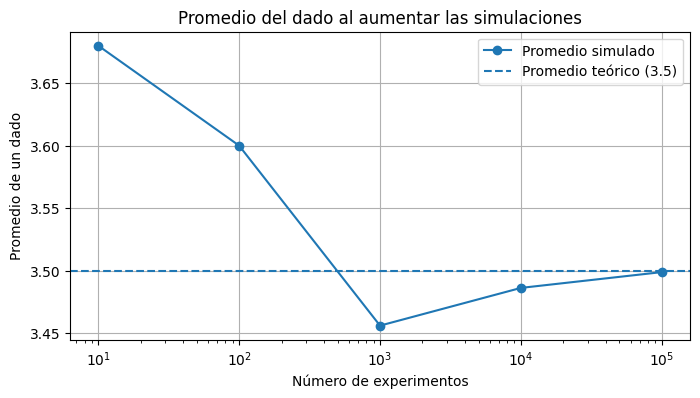

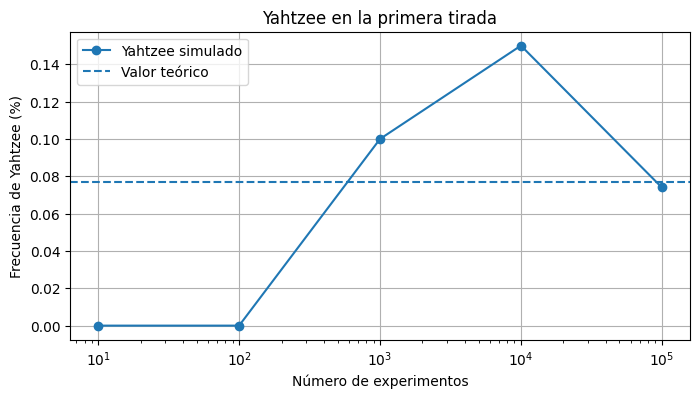

In [15]:
# Las gráficas me ayudan a comparar las simulaciones con la teoría.
import matplotlib.pyplot as plt

x = [fila[0] for fila in resultados]
promedios = [fila[2] for fila in resultados]
frecuencias = [fila[1] * 100 for fila in resultados]

plt.figure(figsize=(8, 4))
plt.plot(x, promedios, marker="o", label="Promedio simulado")
plt.axhline(3.5, linestyle="--", label="Promedio teórico (3.5)")
plt.xscale("log")
plt.xlabel("Número de experimentos")
plt.ylabel("Promedio de un dado")
plt.title("Promedio del dado al aumentar las simulaciones")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(x, frecuencias, marker="o", label="Yahtzee simulado")
plt.axhline(probabilidad_teorica * 100, linestyle="--", label="Valor teórico")
plt.xscale("log")
plt.xlabel("Número de experimentos")
plt.ylabel("Frecuencia de Yahtzee (%)")
plt.title("Yahtzee en la primera tirada")
plt.legend()
plt.grid(True)
plt.show()

## 4. CREA: juego de Yahtzee para dos jugadores

Ahora voy a agregar lo que no estaba en el ejercicio de π: dos jugadores, turnos, lanzamientos y una tabla de puntos.

**Reglas que voy a usar:** cada jugador tiene 13 turnos y hasta 3 lanzamientos por turno. Entre lanzamientos puede guardar los dados que le sirven. Al final del turno debe escoger una casilla que todavía no haya utilizado. Gana quien consiga más puntos.

También incluyo el bono de **35 puntos** en la parte superior cuando se consiguen al menos 63 puntos y las reglas de Yahtzee adicional de **100 puntos**, cuando corresponda.

Primero escribo las funciones de dados y puntajes. Después armo la partida.

In [16]:
# Casillas de puntuación del Yahtzee clásico.
SUPERIORES = ["Unos", "Doses", "Treses", "Cuatros", "Cincos", "Seises"]
INFERIORES = ["Trío", "Póker", "Full house", "Escalera corta", "Escalera larga", "Yahtzee", "Chance"]
CATEGORIAS = SUPERIORES + INFERIORES


def lanzar_dados(dados_anteriores=None, guardar=None):
    """Lanza los cinco dados o solo los que no se guardaron."""
    if dados_anteriores is None:
        return [random.randint(1, 6) for _ in range(5)]

    if guardar is None:
        guardar = []
    nuevos = dados_anteriores.copy()
    for i in range(5):
        # Las posiciones se muestran del 1 al 5, no desde cero.
        if i + 1 not in guardar:
            nuevos[i] = random.randint(1, 6)
    return nuevos


def es_yahtzee(dados):
    return len(set(dados)) == 1


def calcular_puntos(dados, categoria, comodin=False):
    cantidad = [dados.count(numero) for numero in range(1, 7)]
    valores = set(dados)

    if categoria in SUPERIORES:
        numero = SUPERIORES.index(categoria) + 1
        return dados.count(numero) * numero
    if categoria == "Trío":
        return sum(dados) if max(cantidad) >= 3 else 0
    if categoria == "Póker":
        return sum(dados) if max(cantidad) >= 4 else 0
    if categoria == "Full house":
        return 25 if comodin or sorted(c for c in cantidad if c > 0) == [2, 3] else 0
    if categoria == "Escalera corta":
        escaleras = [{1,2,3,4}, {2,3,4,5}, {3,4,5,6}]
        return 30 if comodin or any(e.issubset(valores) for e in escaleras) else 0
    if categoria == "Escalera larga":
        return 40 if comodin or valores in ({1,2,3,4,5}, {2,3,4,5,6}) else 0
    if categoria == "Yahtzee":
        return 50 if es_yahtzee(dados) else 0
    if categoria == "Chance":
        return sum(dados)
    raise ValueError("Categoría no reconocida")

In [17]:
# Cada jugador lleva sus puntos en un diccionario separado.
def crear_tarjeta(nombre):
    return {"nombre": nombre,
            "casillas": {categoria: None for categoria in CATEGORIAS},
            "bono_yahtzee": 0}


def categorias_permitidas(tarjeta, dados):
    libres = [c for c in CATEGORIAS if tarjeta["casillas"][c] is None]

    # Si sale otro Yahtzee y la casilla Yahtzee ya se usó,
    # primero se debe intentar anotar en el número correspondiente.
    if es_yahtzee(dados) and tarjeta["casillas"]["Yahtzee"] is not None:
        numero = SUPERIORES[dados[0] - 1]
        if numero in libres:
            return [numero]
        abajo = [c for c in INFERIORES if c in libres]
        if abajo:
            return abajo
        return [c for c in SUPERIORES if c in libres]
    return libres


def puntaje_opcion(tarjeta, dados, categoria):
    # El comodín aplica a ciertas casillas si ya se ocupó el número correspondiente.
    numero = SUPERIORES[dados[0] - 1]
    comodin = (es_yahtzee(dados) and
               tarjeta["casillas"]["Yahtzee"] is not None and
               tarjeta["casillas"][numero] is not None and
               categoria in INFERIORES)
    return calcular_puntos(dados, categoria, comodin)


def anotar_puntos(tarjeta, dados, categoria):
    if categoria not in categorias_permitidas(tarjeta, dados):
        raise ValueError("Esa casilla no está disponible")

    # Solo hay bono extra cuando antes se habían anotado 50 en Yahtzee.
    bono_extra = 100 if (es_yahtzee(dados) and tarjeta["casillas"]["Yahtzee"] == 50) else 0
    puntos = puntaje_opcion(tarjeta, dados, categoria)
    tarjeta["casillas"][categoria] = puntos
    tarjeta["bono_yahtzee"] += bono_extra
    return puntos, bono_extra


def total_jugador(tarjeta):
    casillas = tarjeta["casillas"]
    subtotal = sum(casillas[c] or 0 for c in SUPERIORES)
    bono_superior = 35 if subtotal >= 63 else 0
    puntos_normales = sum(valor or 0 for valor in casillas.values())
    return puntos_normales + bono_superior + tarjeta["bono_yahtzee"]


def mostrar_marcador(jugadores):
    print("\nRESULTADOS")
    print("Categoría".ljust(22), jugadores[0]["nombre"][:12].ljust(14), jugadores[1]["nombre"][:12])
    for c in CATEGORIAS:
        valores = ["-" if j["casillas"][c] is None else str(j["casillas"][c]) for j in jugadores]
        print(c.ljust(22), valores[0].ljust(14), valores[1])
    print("TOTAL".ljust(22), str(total_jugador(jugadores[0])).ljust(14), total_jugador(jugadores[1]))

### Parte interactiva del juego

Las posiciones de los dados van del **1 al 5**. Por ejemplo, si deseo conservar el primer y el tercer dado, escribo `1 3`. Si no quiero seguir lanzando, escribo `x`. Después selecciono el número de la casilla donde quiero guardar los puntos.

La siguiente celda define el juego, pero todavía no lo inicia para que el cuaderno no se quede esperando entradas mientras ejecuto las demás pruebas.

In [25]:
def pedir_dados_para_guardar():
    while True:
        texto = input("Dados que quiero guardar (ej.: 1 3), ENTER=ninguno, x=parar: ").strip().lower()
        if texto == "x":
            return None
        if texto == "":
            return []
        partes = texto.replace(",", " ").split()
        if all(p in ("1", "2", "3", "4", "5") for p in partes) and len(set(partes)) == len(partes):
            return [int(p) for p in partes]
        print("Escribe solamente posiciones de 1 a 5, sin repetir.")


def jugar_yahtzee():
    print("JUEGO DE YAHTZEE - 2 JUGADORES")
    nombre1 = input("Nombre del jugador 1: ").strip() or "Jugador 1"
    nombre2 = input("Nombre del jugador 2: ").strip() or "Jugador 2"
    jugadores = [crear_tarjeta(nombre1), crear_tarjeta(nombre2)]

    for ronda in range(1, 14):
        print(f"\n---------- RONDA {ronda} de 13 ----------")
        for jugador in jugadores:
            print("Turno de:", jugador["nombre"])
            dados = lanzar_dados()
            print("Lanzamiento 1:", dados)

            # Como máximo son tres lanzamientos en cada turno.
            for numero_lanzamiento in (2, 3):
                guardar = pedir_dados_para_guardar()
                if guardar is None or len(guardar) == 5:
                    break
                dados = lanzar_dados(dados, guardar)
                print(f"Lanzamiento {numero_lanzamiento}:", dados)

            opciones = categorias_permitidas(jugador, dados)
            print("Estas son las casillas que puedo usar:")
            for numero, categoria in enumerate(opciones, 1):
                puntos = puntaje_opcion(jugador, dados, categoria)
                print(f"{numero}. {categoria}: {puntos} puntos")

            while True:
                eleccion = input("Número de casilla para anotar: ").strip()
                if eleccion.isdigit() and 1 <= int(eleccion) <= len(opciones):
                    categoria = opciones[int(eleccion) - 1]
                    puntos, bono = anotar_puntos(jugador, dados, categoria)
                    print(f"Se anotaron {puntos} puntos en {categoria}. Bono extra: {bono}")
                    break
                print("Selecciona un número de la lista.")

        mostrar_marcador(jugadores)

    uno, dos = total_jugador(jugadores[0]), total_jugador(jugadores[1])
    if uno > dos:
        print("\nGanó:", jugadores[0]["nombre"])
    elif dos > uno:
        print("\nGanó:", jugadores[1]["nombre"])
    else:
        print("\nLa partida terminó en empate.")
    return jugadores

In [ ]:
jugar_yahtzee()

JUEGO DE YAHTZEE - 2 JUGADORES
Nombre del jugador 1: Daniela 
Nombre del jugador 2: Luis

---------- RONDA 1 de 13 ----------
Turno de: Daniela
Lanzamiento 1: [6, 6, 1, 2, 6]
Dados que quiero guardar (ej.: 1 3), ENTER=ninguno, x=parar: 3
Lanzamiento 2: [5, 2, 1, 5, 2]
Dados que quiero guardar (ej.: 1 3), ENTER=ninguno, x=parar: 2
Lanzamiento 3: [2, 2, 6, 2, 4]
Estas son las casillas que puedo usar:
1. Unos: 0 puntos
2. Doses: 6 puntos
3. Treses: 0 puntos
4. Cuatros: 4 puntos
5. Cincos: 0 puntos
6. Seises: 6 puntos
7. Trío: 16 puntos
8. Póker: 0 puntos
9. Full house: 0 puntos
10. Escalera corta: 0 puntos
11. Escalera larga: 0 puntos
12. Yahtzee: 0 puntos
13. Chance: 16 puntos
Número de casilla para anotar: 3
Se anotaron 0 puntos en Treses. Bono extra: 0
Turno de: Luis
Lanzamiento 1: [3, 4, 5, 4, 1]
Dados que quiero guardar (ej.: 1 3), ENTER=ninguno, x=parar: 2
Lanzamiento 2: [4, 4, 3, 2, 3]
Dados que quiero guardar (ej.: 1 3), ENTER=ninguno, x=parar: 3
Lanzamiento 3: [2, 3, 3, 4, 4]
Est

### 5. Algunas pruebas antes de jugar

Antes de probar una partida completa, voy a revisar unos casos donde ya sé cuál debería ser el resultado. Así puedo detectar errores en los puntos.

In [19]:
assert calcular_puntos([6, 6, 6, 6, 6], "Yahtzee") == 50
assert calcular_puntos([2, 2, 2, 5, 5], "Full house") == 25
assert calcular_puntos([1, 2, 3, 4, 6], "Escalera corta") == 30
assert calcular_puntos([1, 2, 3, 4, 5], "Escalera larga") == 40
assert calcular_puntos([3, 3, 3, 1, 5], "Trío") == 15
assert calcular_puntos([2, 2, 4, 5, 6], "Póker") == 0

prueba = crear_tarjeta("Prueba")
anotar_puntos(prueba, [6, 6, 6, 6, 6], "Yahtzee")
assert categorias_permitidas(prueba, [6, 6, 6, 6, 6]) == ["Seises"]
anotar_puntos(prueba, [6, 6, 6, 6, 6], "Seises")
assert prueba["bono_yahtzee"] == 100

print("Las pruebas de puntuación y del bono Yahtzee terminaron correctamente.")

Las pruebas de puntuación y del bono Yahtzee terminaron correctamente.


### 6. Montecarlo usando hasta tres lanzamientos

En la simulación anterior conté Yahtzees **solo en la primera tirada**. Como el juego permite hasta tres lanzamientos, ahora voy a probar otra situación: conservar en cada intento los dados que más se repiten y relanzar los demás.

Esta es una estrategia sencilla que escogí para el experimento. La probabilidad que obtenga **no se debe comparar directamente con 1/1.296**, porque ese valor solamente corresponde a una tirada.

In [20]:
def simular_tres_lanzamientos(n):
    yahtzees = 0
    for _ in range(n):
        dados = lanzar_dados()
        for intento in range(2):  # Dos intentos adicionales.
            if es_yahtzee(dados):
                break
            # Conservo la cara que más salió.
            valor_mas_repetido = max(range(1, 7), key=lambda v: dados.count(v))
            guardar = [pos for pos, valor in enumerate(dados, 1) if valor == valor_mas_repetido]
            dados = lanzar_dados(dados, guardar)
        if es_yahtzee(dados):
            yahtzees += 1
    return yahtzees / n

random.seed(2026)
frecuencia_tres = simular_tres_lanzamientos(100000)
print(f"Yahtzee con estrategia de hasta 3 lanzamientos: {frecuencia_tres*100:.3f}%")
print(f"Yahtzee en 1 tirada (valor teórico): {probabilidad_teorica*100:.5f}%")

Yahtzee con estrategia de hasta 3 lanzamientos: 4.525%
Yahtzee en 1 tirada (valor teórico): 0.07716%


### 7. Prueba automática de una partida

Para no tener que escribir 26 turnos mientras reviso el cuaderno, hago una partida de prueba con dos jugadores automáticos. Cada jugador conserva los dados más repetidos y escoge la casilla disponible que da más puntos en ese momento. **No significa que esa sea la mejor estrategia del juego**, solo me permite verificar que las 13 casillas se llenan y que hay un resultado final.

In [21]:
def partida_de_prueba():
    random.seed(2026)
    jugadores = [crear_tarjeta("Jugador 1"), crear_tarjeta("Jugador 2")]
    for ronda in range(13):
        for jugador in jugadores:
            dados = lanzar_dados()
            for intento in range(2):
                valor = max(range(1, 7), key=lambda v: dados.count(v))
                guardar = [pos for pos, d in enumerate(dados, 1) if d == valor]
                dados = lanzar_dados(dados, guardar)
            opciones = categorias_permitidas(jugador, dados)
            mejor = max(opciones, key=lambda c: puntaje_opcion(jugador, dados, c))
            anotar_puntos(jugador, dados, mejor)

    # Deben quedar usadas las 13 casillas de cada jugador.
    assert all(all(v is not None for v in j["casillas"].values()) for j in jugadores)
    mostrar_marcador(jugadores)
    print("Partida de prueba completada: 13 turnos por jugador.")

partida_de_prueba()


RESULTADOS
Categoría              Jugador 1      Jugador 2
Unos                   0              0
Doses                  0              2
Treses                 6              6
Cuatros                4              16
Cincos                 15             20
Seises                 24             12
Trío                   8              18
Póker                  17             18
Full house             0              25
Escalera corta         30             0
Escalera larga         0              0
Yahtzee                50             0
Chance                 20             27
TOTAL                  174            144
Partida de prueba completada: 13 turnos por jugador.


### 8. Jugar una partida manual

La celda siguiente tiene el juego listo, pero está comentada para que pueda ejecutar todas las celdas sin que aparezcan preguntas por pantalla. Si quiero jugar con otra persona, **quito el `#` y ejecuto esa celda**.

In [27]:
# Quitar el símbolo # de esta línea para iniciar el juego:
# jugar_yahtzee()

## 9. Resultados y conclusiones

Con este ejercicio puedo relacionar la idea que vimos en clase con un juego de dados. En el código de π se cuentan puntos dentro de un cuarto de círculo; en mi adaptación se cuentan las veces que aparecen cinco dados iguales.

La simulación muestra que al aumentar la cantidad de experimentos el promedio de un dado se acerca a **3,5** y la frecuencia de Yahtzee en una tirada se aproxima a **0,07716 %**. Es importante recordar que los valores cambian por azar y que la cercanía no tiene por qué mejorar en todos los intentos.

El programa también incluye un juego para dos jugadores, con un máximo de tres lanzamientos por turno, casillas de puntuación y resultado final. La parte que me pareció más útil fue comprobar que con el mismo ciclo `for`, una condición `if` y un contador se pueden estudiar diferentes situaciones aleatorias.

**Lo que me falta para entregar:** ejecutar este cuaderno en mi cuenta de Colab, revisar sus resultados, subirlo a GitHub y grabar el video de máximo cinco minutos mostrando los cambios.

**Referencias usadas:**
- Código de estimación de π compartido por el profesor en clase de Ingeniería de Simulación.
- Python Software Foundation. Documentación del módulo `random`: https://docs.python.org/3/library/random.html
- Hasbro. Juego Yahtzee y sus reglas: https://instructions.hasbro.com/en-us/instruction/yahtzee